In [4]:
import re
from math import sqrt, floor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.action_chains import ActionChains

# Question 1

In [21]:
# Import Auto.csv (also, iris)
auto = pd.read_csv("Auto.csv")
auto

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
392,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
393,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
394,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
395,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [3]:
# Check the data types of each column
auto.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
year              int64
origin            int64
name             object
dtype: object

In [22]:
# Try to recode horsepower as numeric (pd.to_numeric or Series.astype)
auto["horsepower"] = auto["horsepower"].astype("int64") # ERROR
# Alternatively:
# auto["horsepower"] = auto["horsepower"].pipe(pd.to_numeric) # ERROR
# auto["horsepower"] 

ValueError: invalid literal for int() with base 10: '?'

In [26]:
# Print weird elements
_ = auto["horsepower"].apply(lambda x: x if x.isnumeric() else print(x))

?
?
?
?
?


In [31]:
# Replace erroneous data points with pd.NA types
b = auto["horsepower"].pipe(pd.to_numeric, errors="coerce")
auto
# Alternatively:
# auto["horsepower"].apply(lambda x: x if x.isnumeric() else pd.NA).pipe(to_numeric)

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
392,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
393,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
394,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
395,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [8]:
## a)
auto.columns

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'origin', 'name'],
      dtype='object')

In [9]:
non_predictors = ["mpg"]
quant_predictors = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "year"]
quali_predictors = ["origin", "name"]

In [10]:
## b,c)
# Subset columns and describe them
auto[quant_predictors].describe()

,cylinders,displacement,horsepower,weight,acceleration,year
count,397.000000,397.000000,392.000000,397.000000,397.000000,397.000000
mean,5.458438,193.532746,104.469388,2970.261965,15.555668,75.994962
std,1.701577,104.379583,38.491160,847.904119,2.749995,3.690005
min,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,4.000000,104.000000,75.000000,2223.000000,13.800000,73.000000
50%,4.000000,146.000000,93.500000,2800.000000,15.500000,76.000000
75%,8.000000,262.000000,126.000000,3609.000000,17.100000,79.000000
max,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [11]:
## d)
# Drop observations 10 through 85 and find min, max, mean, and std
auto.drop(range(10, 86), axis=0)[quant_predictors].describe()
# Alternatively:
# pd.concat([auto.iloc[0:10], auto.iloc[86:]])

,cylinders,displacement,horsepower,weight,acceleration,year
count,321.000000,321.000000,317.000000,321.000000,321.000000,321.000000
mean,5.370717,187.174455,101.003155,2933.183801,15.709034,77.143302
std,1.653486,99.864568,36.003208,809.638650,2.706441,3.128202
min,3.000000,68.000000,46.000000,1649.000000,8.500000,70.000000
25%,4.000000,100.000000,75.000000,2215.000000,14.000000,75.000000
50%,4.000000,145.000000,90.000000,2795.000000,15.500000,77.000000
75%,6.000000,250.000000,115.000000,3504.000000,17.300000,80.000000
max,8.000000,455.000000,230.000000,4997.000000,24.800000,82.000000


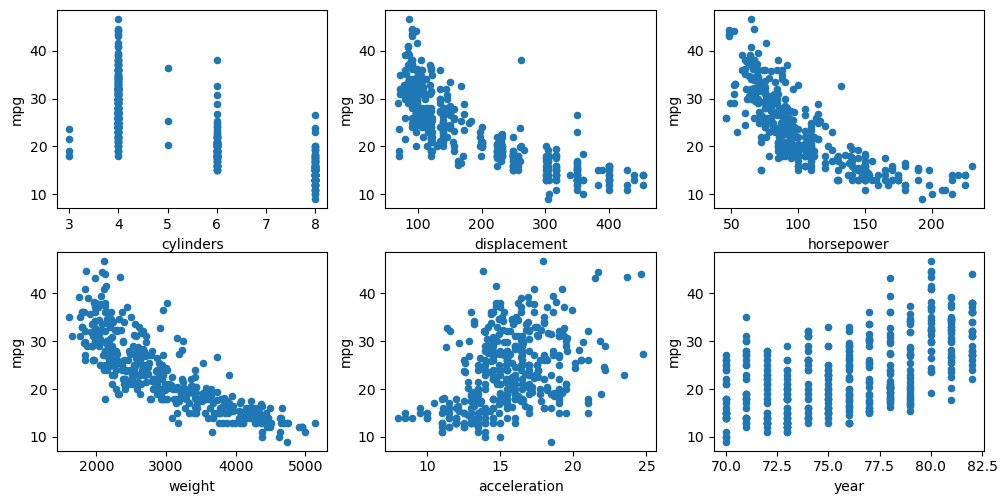

In [12]:
## e)
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(10,5))
fig.tight_layout()

for qp, ax in zip(quant_predictors, axs.reshape(-1)):
    auto.plot(x=qp, y="mpg", kind="scatter", ax=ax)
    
    
# auto.plot(kind='scatter', x='displacement', y='weight', color='r')

# Question 2

C:\Users\seyye\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3526: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


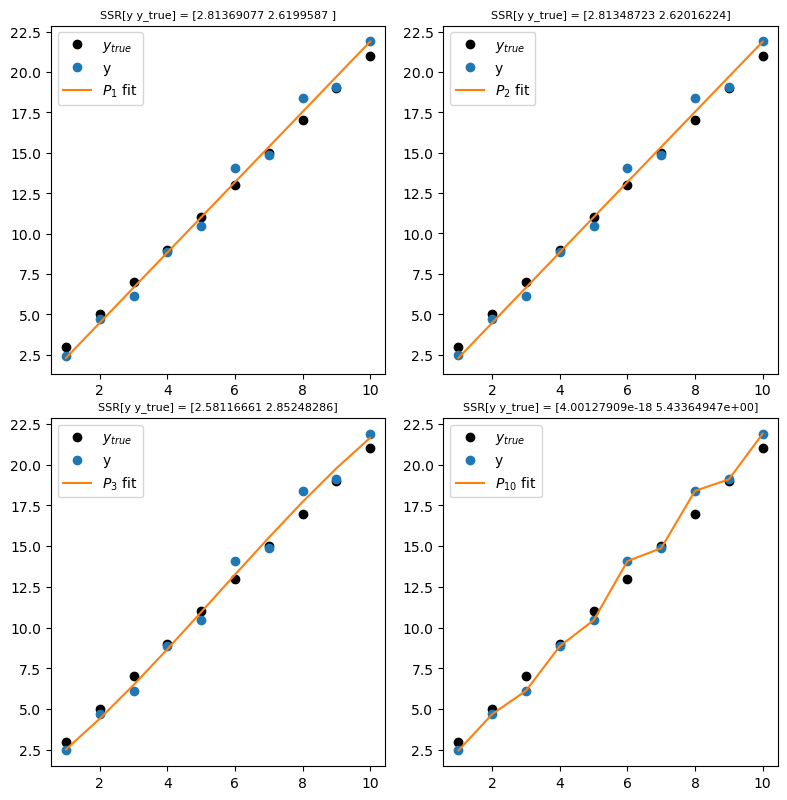

In [19]:
# This code shows that polynomials with higher degrees are more flexible and 
# so can fit the training data better

# NOTE: This section is more an aide to the discussion around question 2
# Rather than an answer to the question on it's own
a = 1
b =2 
std=1
n=10
degrees=None

# Why do this when we could have done degrees=[1,2,3]?
if degrees is None:
    degrees = [1,2,3]

x = np.arange(1, n+1)
y_true = a + b*x
y = y_true + np.random.normal(0, std, n)

# non-mutating
degrees = degrees + [n]

ndeg = len(degrees)
nrows = floor(sqrt(ndeg))
ncols = ndeg // nrows

fig, axs = plt.subplots(nrows=nrows, ncols=ncols, 
                        figsize=tuple([n*4 for n in [nrows, ncols]]))
fig.tight_layout()

for deg, ax in zip(degrees, axs.reshape(-1)):

    coeffs = np.polyfit(x, y, deg)
    # What's happening here?
    # How can we explore what np.poly1d is doing?
    poly_fit = np.poly1d(coeffs)(x)
    ssr = ((np.array([y, y_true]) - poly_fit)**2).sum(axis=1)

    ax.plot(x, y_true, "o", c="black", label="$y_{true}$")
    ax.plot(x, y, "o", label="y")
    # Why so many curly braces?
    ax.plot(x, poly_fit, label=f"$P_{{{deg}}}$ fit")
    ax.legend()
    ax.set_title(f"SSR[y y_true] = {ssr}", size=8)



# Question 3

In [55]:
from selenium.webdriver.chrome.service import Service
from webdriver_manager.chrome import ChromeDriverManager
#use selenium v4 
driver = webdriver.Chrome()
# driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))
# driver = webdriver.Chrome(executable_path='C:\Program Files\Google\Chrome\Application\chromedriver')

a = ActionChains(driver)


In [56]:
driver.get("https://finance.yahoo.com/")
driver.maximize_window()

In [57]:
elems = driver.find_elements(By.LINK_TEXT, "News")
elems


[<selenium.webdriver.remote.webelement.WebElement (session="526dc022d371ec8b3d3f9b89042c8ac1", element="f.7121C69853B3C83F30FC2EABA9CB8765.d.342E643CE1F705B5DA30C12EA67472F7.e.99")>,
 <selenium.webdriver.remote.webelement.WebElement (session="526dc022d371ec8b3d3f9b89042c8ac1", element="f.7121C69853B3C83F30FC2EABA9CB8765.d.342E643CE1F705B5DA30C12EA67472F7.e.3")>]

In [58]:
dir(elems[0])

['__abstractmethods__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_execute',
 '_id',
 '_parent',
 '_upload',
 'accessible_name',
 'aria_role',
 'clear',
 'click',
 'find_element',
 'find_elements',
 'get_attribute',
 'get_dom_attribute',
 'get_property',
 'id',
 'is_displayed',
 'is_enabled',
 'is_selected',
 'location',
 'location_once_scrolled_into_view',
 'parent',
 'rect',
 'screenshot',
 'screenshot_as_base64',
 'screenshot_as_png',
 'send_keys',
 'shadow_root',
 'size',
 'submit',
 'tag_name',
 'text',
 'value_of_css_property']

In [59]:
for i, elem in enumerate(elems):
    elem.screenshot(f"ss{i}.png")

In [60]:
a.move_to_element(elems[1]).perform()
elem = driver.find_element(By.LINK_TEXT, "Latest")
elem.click()

In [42]:
elem = driver.find_element(By.CLASS_NAME, "titles")
elem.click()

In [43]:
elem = driver.find_element(By.CLASS_NAME, "body")
elems = elem.find_elements(By.XPATH, ".//*")

In [54]:
title = driver.title

text = ''
for elem in elems:
        text += elem.text
text

'By Kumar Tanishk(Reuters) - Shares of Qantas rose to a record high on Thursday, a day after the Australian carrier unveiled changes to its frequent fliers programme to attract cost-conscious travellers and restore its credibility following a string of controversies.Qantas\' stock advanced 0.5% to finish the day at an all-time high of A$9.420. Earlier in the day, shares climbed as much as 1.7% to record levels of A$9.54.The overhaul of the frequent flyer programme, set to roll out in the next 12 months, comes after a challenging couple of years for the flagship carrier, which was marked with controversies like the sale of thousands of tickets on already cancelled flights.This move is seen as a strategy to boost loyalty among members and increase revenue from the programme. It builds on last year\'s revamp, which included offering access to 20 million additional reward seats available for purchase with points.Qantas Loyalty generated roughly A$2.5 billion ($1.57 billion) in revenue for 